# 04 · Modelo de demanda por estación: ¿qué hace que una estación tenga pasajeros?

**Pregunta:** ¿de qué depende el número de abordajes de una estación y cuántos pasajeros al año podría
captar una estación nueva?

**Datos** (`teleferico.demand_model`):
- **Variable respuesta:** abordajes estimados de 2025 por estación física (ranking del PDF de Mi Teleférico,
  % con un decimal × total del año; error de ±0,05 pp × 87,7 M ≈ ±44 mil por andén). Los andenes de una
  estación de transbordo se suman.
- **Variables candidatas:** población a ≤ 15 min a pie con pendiente (notebook 03), población del "área de
  alimentación" (estación más cercana en línea recta, a ≤ 3 km), cabecera de línea, línea que une El Alto con
  La Paz, transbordo, municipio, distancia al centro y años de operación.

**Método:** regresión **binomial negativa** (los conteos tienen mucha sobredispersión), con pocos modelos
simples y validación **leave-one-out** (LOO). Con **n = 26** se evita sobreinterpretar: se prefieren modelos
de 1-2 variables y se reportan intervalos.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

from teleferico import demand_model as dm
from teleferico import demanda, viz

viz.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

t = demanda.cargar()
df = dm.variables(t)
print("Líneas que unen El Alto con La Paz:", dm.lineas_interurbanas(t))
cols = ["nombre", "municipio", "lineas", "y", "pob_15", "pob_voronoi_3km", "cabecera", "interurbana",
        "cabecera_interurbana", "transbordo", "dist_centro_km", "anios_operacion"]
df[cols].sort_values("y", ascending=False).set_index("nombre").style.format(
    {"y": viz.fmt_int, "pob_15": viz.fmt_int, "pob_voronoi_3km": viz.fmt_int, "dist_centro_km": "{:.1f}"})

Líneas que unen El Alto con La Paz: ['Amarilla', 'Morada', 'Roja']


,municipio,lineas,y,pob_15,pob_voronoi_3km,cabecera,interurbana,cabecera_interurbana,transbordo,dist_centro_km,anios_operacion
nombre,,,,,,,,,,,
16 de Julio,El Alto,"Azul, Plateada, Roja",13.238.503,10.423,27.439,1,1,1,1,3.3,12
San José,La Paz,Morada,10.432.993,40.150,27.080,1,1,1,0,0.5,8
Libertador,La Paz,"Amarilla, Celeste, Verde",9.468.598,1.942,13.723,1,1,1,1,3.2,12
Mirador,El Alto,"Amarilla, Plateada",8.504.204,21.185,42.916,1,1,1,1,3.0,12
Faro Murillo,El Alto,"Morada, Plateada",7.189.121,21.785,27.883,1,1,1,1,2.8,8
6 de Marzo,El Alto,Morada,6.750.760,10.880,88.774,1,1,1,0,4.8,8
Estación Central,La Paz,"Naranja, Roja",6.663.088,25.406,43.573,1,1,1,1,1.3,12
Héroes de la Revolución,La Paz,"Blanca, Naranja",3.857.577,32.230,75.391,1,0,0,1,1.8,9
Rio Seco,El Alto,Azul,2.717.838,20.048,124.786,1,0,0,0,8.1,9


## 1. Exploración: la demanda la mueven las "puertas" entre El Alto y La Paz

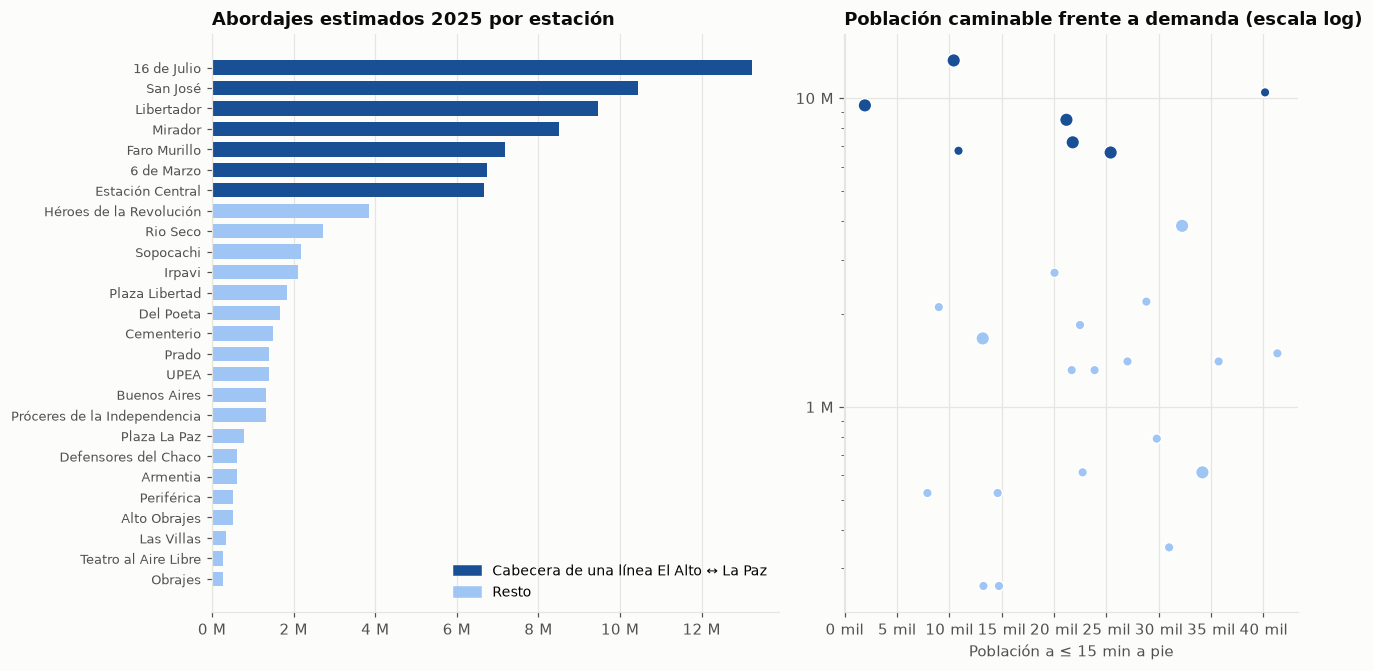

,Spearman con log(abordajes)
cabecera_interurbana,0.769
interurbana,0.691
cabecera,0.618
transbordo,0.517
el_alto,0.406
l_pob_voronoi_3km,0.176
anios_operacion,0.164
dist_centro_km,0.151
l_pob_15,-0.077


In [2]:
d = df.sort_values("y")
COL = {1: viz.SECUENCIAL[5], 0: viz.SECUENCIAL[1]}
fig, axs = plt.subplots(1, 2, figsize=(12, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axs[0]
ax.barh(d["nombre"], d["y"], color=d["cabecera_interurbana"].map(COL), height=0.7)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(viz.millones))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
ax.legend(handles=[Patch(color=COL[1], label="Cabecera de una línea El Alto ↔ La Paz"),
                   Patch(color=COL[0], label="Resto")], loc="lower right", fontsize=9)
ax.set_title("Abordajes estimados 2025 por estación")

ax = axs[1]
for v, g in df.groupby("cabecera_interurbana"):
    ax.scatter(g["pob_15"], g["y"], color=COL[v], s=np.where(g["transbordo"] == 1, 80, 40), edgecolor="white", zorder=3)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: viz.millones(x) if x >= 1e6 else viz.miles(x)))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(viz.miles))
ax.set_xlabel("Población a ≤ 15 min a pie")
ax.set_title("Población caminable frente a demanda (escala log)")
fig.tight_layout()
viz.guardar(fig, "04_exploracion")
plt.show()

rho = df[["l_pob_15", "l_pob_voronoi_3km", "cabecera", "interurbana", "cabecera_interurbana", "transbordo",
          "el_alto", "dist_centro_km", "anios_operacion"]].corrwith(np.log(df["y"]), method="spearman")
rho.sort_values(ascending=False).to_frame("Spearman con log(abordajes)")

**Lectura:**
- Las **7 estaciones con más abordajes son exactamente las cabeceras de las 3 líneas que unen El Alto con La
  Paz** (Roja, Amarilla y Morada): 16 de Julio, Mirador, Faro Murillo y 6 de Marzo arriba; San José,
  Libertador y Estación Central abajo. Juntas suman el **71 % de los abordajes**, con entre 6,7 y 13,2 M cada
  una. La octava (Héroes de la Revolución) ya baja a 3,9 M.
- La correlación más alta con la demanda es la de esa variable (ρ = 0,77). Siguen la línea interurbana
  (0,69), la cabecera de cualquier línea (0,62) y el transbordo (0,52).
- **La población caminable no se asocia con la demanda** (ρ = −0,08), y el área de alimentación de 3 km
  apenas lo hace (0,18). Confirma lo visto en el notebook 03: las estaciones grandes captan viajes que
  llegan en minibús y transbordo, no de su vecindario.

## 2. Comparación de modelos (binomial negativa, validación leave-one-out)

Métricas LOO: cada estación se predice con un modelo ajustado sin ella. `loo_mae` es el error absoluto medio
en pasajeros/año, `loo_dev_poisson` la devianza de Poisson media (castiga más los errores relativos en
estaciones chicas) y `loo_r2_log` el R² en escala logarítmica.

In [3]:
comp, preds = dm.comparar(df)
comp.drop(columns="formula").sort_values("loo_dev_poisson").style.format({
    "aic": "{:.1f}", "pseudo_r2": "{:.3f}", "alpha": "{:.2f}", "loo_mae": lambda x: f"{x / 1e6:.2f} M",
    "loo_dev_poisson": lambda x: f"{x / 1e3:,.0f} mil", "loo_mape_mediana": "{:.0f} %", "loo_r2_log": "{:.2f}"})

,n_coef,aic,pseudo_r2,alpha,loo_mae,loo_dev_poisson,loo_mape_mediana,loo_r2_log
modelo,,,,,,,,
Cabecera interurbana,2,807.0,0.039,0.38,1.13 M,691 mil,39 %,0.60
Cab. interurbana + transbordo,3,807.4,0.041,0.36,1.28 M,823 mil,45 %,0.58
Cabecera + interurbana + transbordo,4,806.1,0.045,0.32,1.25 M,838 mil,47 %,0.60
Cab. interurbana + transbordo + área alim.,4,806.0,0.045,0.32,1.58 M,926 mil,50 %,0.60
Cab. interurbana + transbordo + pob. a pie,4,809.0,0.041,0.35,1.49 M,957 mil,51 %,0.57
Cabecera,2,820.9,0.022,0.60,2.33 M,"2,166 mil",55 %,0.21
Nulo,1,837.4,-0.000,1.06,3.13 M,"3,760 mil",118 %,-0.35
Población a pie,2,838.0,0.002,1.02,3.08 M,"3,848 mil",101 %,-0.36
Área de alimentación,2,839.3,0.000,1.06,3.23 M,"4,068 mil",111 %,-0.41


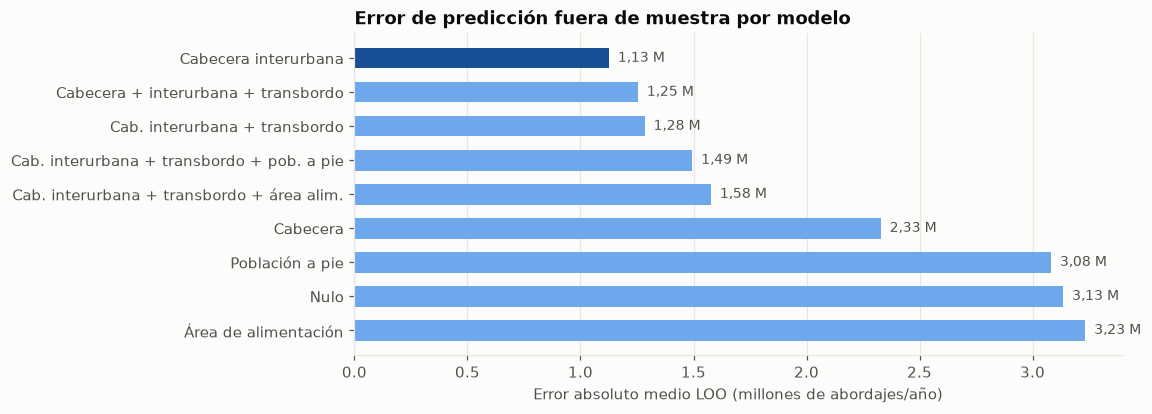

In [4]:
c = comp.sort_values("loo_mae")
fig, ax = plt.subplots(figsize=(9, 3.8))
colores = [viz.SECUENCIAL[5] if i == 0 else viz.SECUENCIAL[2] for i in range(len(c))]
ax.barh(c.index, c["loo_mae"] / 1e6, color=colores, height=0.6)
for i, v in enumerate(c["loo_mae"] / 1e6):
    ax.text(v + 0.04, i, f"{viz.num(v, 2)} M", va="center", fontsize=9, color=viz.TINTA_2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Error absoluto medio LOO (millones de abordajes/año)")
ax.set_title("Error de predicción fuera de muestra por modelo")
viz.guardar(fig, "04_comparacion_modelos")
plt.show()

**Lectura:**
- El mejor modelo fuera de muestra es el más simple: **solo `cabecera_interurbana`** (error LOO de 1,13 M
  frente a 3,13 M del modelo nulo; R² LOO en log de 0,60).
- Agregar transbordo, población a pie o área de alimentación **empeora** el error LOO (1,25-1,58 M). Con
  26 estaciones, cada variable extra sobreajusta.
- Los modelos con solo población son tan malos como el nulo. **La hipótesis 3 del plan no se sostiene tal
  como estaba planteada:** la demanda observada no se explica por la población del área de influencia a pie,
  sino por el **rol de la estación en la red**.

## 3. Modelos elegidos

- **Principal:** `cabecera_interurbana` (menor error LOO).
- **Extendido** (para la sensibilidad del notebook 05): `cabecera_interurbana + transbordo + log(pob. a pie)`.
  Su error LOO es algo mayor, pero permite que la población caminable mueva la predicción.

Los coeficientes se leen como **multiplicadores** (exp(β)): cuántas veces más abordajes tiene una estación con
el atributo, o por cada vez que se multiplica por *e* la población.

In [5]:
principal = dm.ajustar(dm.MODELOS["Cabecera interurbana"], df)
extendido = dm.ajustar(dm.MODELOS["Cab. interurbana + transbordo + pob. a pie"], df)

def multiplicadores(res):
    ci = res.conf_int()
    out = pd.DataFrame({"coef": res.params, "p_valor": res.pvalues, "ic95_inf": ci[0], "ic95_sup": ci[1]})
    out = out.drop(index="alpha")
    out[["exp_coef", "exp_inf", "exp_sup"]] = np.exp(out[["coef", "ic95_inf", "ic95_sup"]])
    return out

print(f"Principal: alpha = {principal.params['alpha']:.2f}; base (estación común) = "
      f"{viz.fmt_int(np.exp(principal.params['Intercept']))} abordajes/año")
display(multiplicadores(principal))
print(f"Extendido: alpha = {extendido.params['alpha']:.2f}")
multiplicadores(extendido)

Principal: alpha = 0.38; base (estación común) = 1.328.926 abordajes/año


,coef,p_valor,ic95_inf,ic95_sup,exp_coef,exp_inf,exp_sup
Intercept,14.100,0.000,13.824,14.376,"1,328,926.000","1,008,486.473","1,751,182.946"
cabecera_interurbana,1.901,0.000,1.369,2.433,6.691,3.932,11.388


Extendido: alpha = 0.35


,coef,p_valor,ic95_inf,ic95_sup,exp_coef,exp_inf,exp_sup
Intercept,13.921,0.000,13.511,14.332,"1,111,508.619","737,228.113","1,675,806.156"
cabecera_interurbana,1.778,0.000,1.177,2.380,5.920,3.245,10.802
transbordo,0.386,0.180,-0.178,0.949,1.471,0.837,2.584
l_pob_15,0.122,0.505,-0.238,0.483,1.130,0.788,1.620


**Lectura:**
- Una estación "común" capta en promedio **~1,3 M de abordajes/año** (IC 95 % de la media: 1,0-1,8 M).
- Ser cabecera de una línea El Alto ↔ La Paz **multiplica la demanda por ~6,7** (IC 95 %: 3,9-11,4).
- En el modelo extendido, el transbordo multiplica por 1,5 y duplicar la población a pie, por ~1,09
  (elasticidad 0,12). **Ninguno de los dos es significativo** (p = 0,18 y 0,51), así que el modelo
  extendido solo se usa como sensibilidad.
- La sobredispersión es alta (α ≈ 0,35-0,38): incluso con el mismo perfil, las estaciones varían mucho.

## 4. Predicción fuera de muestra (LOO) frente a lo observado

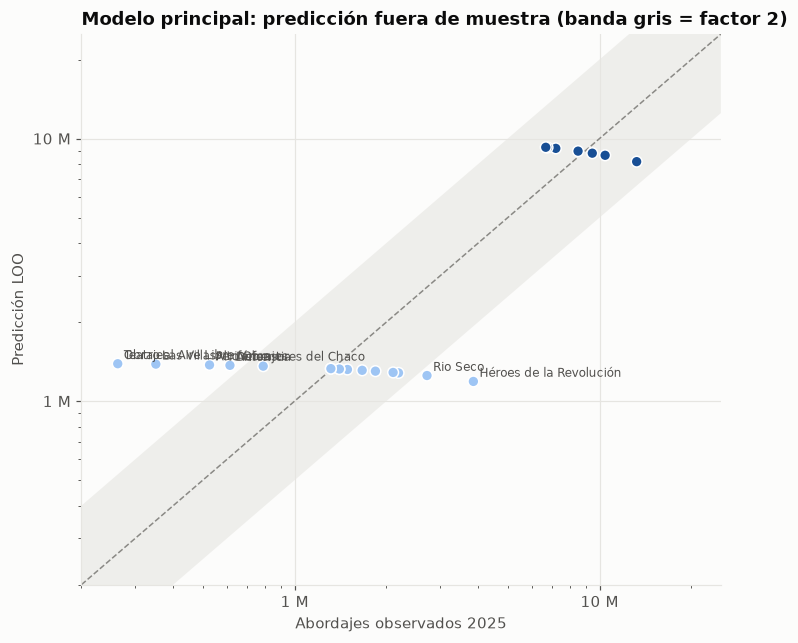

Estaciones con predicción LOO dentro de un factor 2: 65 %


In [6]:
p = preds["Cabecera interurbana"].rename("pred").to_frame().join(df.set_index("slug")[["nombre", "y", "cabecera_interurbana"]])
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(p["y"], p["pred"], c=p["cabecera_interurbana"].map(COL), s=50, edgecolor="white", zorder=3)
lim = [2e5, 2.5e7]
ax.plot(lim, lim, color=viz.TINTA_3, lw=1, ls="--")
ax.fill_between(lim, [x / 2 for x in lim], [x * 2 for x in lim], color=viz.GRILLA, alpha=0.6, lw=0)
for r in p.itertuples():
    if r.pred / r.y > 2 or r.y / r.pred > 2:
        ax.annotate(r.nombre, (r.y, r.pred), xytext=(4, 3), textcoords="offset points", fontsize=8, color=viz.TINTA_2)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lim)
ax.set_ylim(lim)
fmt = mticker.FuncFormatter(lambda x, _: viz.millones(x) if x >= 1e6 else viz.miles(x))
ax.xaxis.set_major_formatter(fmt)
ax.yaxis.set_major_formatter(fmt)
ax.set_xlabel("Abordajes observados 2025")
ax.set_ylabel("Predicción LOO")
ax.set_title("Modelo principal: predicción fuera de muestra (banda gris = factor 2)")
viz.guardar(fig, "04_loo")
plt.show()
dentro = ((p["pred"] / p["y"]).between(0.5, 2)).mean() * 100
print(f"Estaciones con predicción LOO dentro de un factor 2: {dentro:.0f} %")

## 5. Contraste: demanda acumulada 2014-2025

El plan propone usar el acumulado como contraste. Como las líneas abrieron en años distintos, se usa el
**promedio anual** del acumulado (acumulado / años de operación) con el mismo modelo.

In [7]:
acum = demanda.estaciones_fisicas(t, periodo="2014_2025")[["slug", "pasajeros_est"]].rename(
    columns={"pasajeros_est": "acumulado"})
df_ac = df.merge(acum, on="slug")
df_ac["y"] = (df_ac["acumulado"] / df_ac["anios_operacion"]).round()
filas = []
for nombre in ["Cabecera interurbana", "Cab. interurbana + transbordo + pob. a pie"]:
    for etiqueta, datos in (("2025", df), ("Promedio 2014-2025", df_ac)):
        r = dm.ajustar(dm.MODELOS[nombre], datos)
        filas.append({"modelo": nombre, "respuesta": etiqueta,
                      **{f"exp({k})": np.exp(v) for k, v in r.params.drop("alpha").items()}})
pd.DataFrame(filas).set_index(["modelo", "respuesta"])

exp(Intercept)  \
modelo                                     respuesta                            
Cabecera interurbana                       2025                 1,328,926.000   
                                           Promedio 2014-2025   1,105,100.421   
Cab. interurbana + transbordo + pob. a pie 2025                 1,111,508.619   
                                           Promedio 2014-2025     888,472.238   

                                                               exp(cabecera_interurbana)  \
modelo                                     respuesta                                       
Cabecera interurbana                       2025                                    6.691   
                                           Promedio 2014-2025                      5.831   
Cab. interurbana + transbordo + pob. a pie 2025                                    5.920   
                                           Promedio 2014-2025                      5.142   

                                                               exp(transbordo)  \
modelo                                     respuesta                             
Cabecera interurbana                       2025                            NaN   
                                           Promedio 2014-2025              NaN   
Cab. interurbana + transbordo + pob. a pie 2025                          1.471   
                                           Promedio 2014-2025            1.572   

                                                               exp(l_pob_15)  
modelo                                     respuesta                          
Cabecera interurbana                       2025                          NaN  
                                           Promedio 2014-2025            NaN  
Cab. interurbana + transbordo + pob. a pie 2025                        1.130  
                                           Promedio 2014-2025          1.155

**Lectura:** con el promedio anual del acumulado 2014-2025, la estructura se mantiene: la cabecera
interurbana multiplica por 5,8 (frente a 6,7 en 2025) y la base es de ~1,1 M. **El hallazgo no es un
efecto de 2025:** es estructural desde que existe la red.

## 6. Predicción para estaciones hipotéticas (con intervalos)

Se simulan 5.000 escenarios: los coeficientes se toman de su distribución estimada y los pasajeros de una
binomial negativa. El intervalo del 90 % refleja la incertidumbre del modelo **y** la variabilidad entre
estaciones, que es muy grande.

In [8]:
escenarios = dm.transformar(pd.DataFrame({
    "escenario": ["Estación común (sin transbordo), 20 mil vecinos a pie",
                  "Estación común (sin transbordo), 40 mil vecinos a pie",
                  "Estación de transbordo, 20 mil vecinos a pie",
                  "Cabecera de una nueva línea El Alto ↔ La Paz"],
    "cabecera_interurbana": [0, 0, 0, 1], "transbordo": [0, 0, 1, 0],
    "pob_15": [20_000, 40_000, 20_000, 20_000], "pob_voronoi_3km": [50_000] * 4,
}))
filas = []
for nombre, res in (("Principal", principal), ("Extendido", extendido)):
    sim = dm.simular(res, escenarios)
    for i, e in enumerate(escenarios["escenario"]):
        filas.append({"modelo": nombre, "escenario": e, **dm.intervalo(sim[:, i])})
pred = pd.DataFrame(filas).set_index(["escenario", "modelo"]).sort_index()
pred.style.format(lambda x: f"{x / 1e6:,.2f} M")

**Lectura:**
- Una estación nueva **común** (sin transbordo ni rol de puerta El Alto ↔ La Paz) captaría **~1,2-1,3 M de
  abordajes/año**, con un intervalo del 90 % muy amplio (0,3-3,0 M). Pasar de 20 a 40 mil vecinos a pie
  casi no cambia la predicción.
- Una **nueva cabecera El Alto ↔ La Paz** captaría ~7,5-9 M (1,7-21 M): un orden de magnitud más.
- El modelo sobreestima las estaciones chicas de La Paz (Las Villas, Obrajes, Teatro al Aire Libre: 0,26-0,35 M
  observados frente a ~1,4 M predichos) y subestima Héroes de la Revolución y Río Seco. **El 65 % de las
  estaciones queda dentro de un factor 2** en la validación LOO.

## 7. Conclusiones

| # | Hallazgo | Implicación |
|---|---|---|
| 1 | Las 7 cabeceras de las líneas Roja, Amarilla y Morada concentran el 71 % de los abordajes | La red funciona como un **sistema de puertas entre El Alto y La Paz** alimentado por minibús |
| 2 | El mejor modelo (LOO) usa una sola variable, `cabecera_interurbana`: ×6,7 sobre una base de ~1,3 M/año | Simple, estable (se repite con el acumulado 2014-2025) y fácil de comunicar |
| 3 | La población a pie no explica la demanda (ρ = −0,08; no significativa en el modelo) | La **hipótesis 3 se reformula**: la población del área de influencia explica poco. Pesa el rol en la red |
| 4 | Error LOO de 1,13 M/año; 65 % de las estaciones dentro de un factor 2; intervalos de predicción muy amplios | Las estimaciones de pasajeros de la Fase 5 son **órdenes de magnitud**, no pronósticos |
| 5 | Una estación común nueva: ~1,3 M/año (IC 90 %: 0,3-3,0 M). Una nueva puerta El Alto ↔ La Paz: ~7,5-9 M | Para la demanda, **conectar El Alto con La Paz** vale más que cubrir vecindarios |

**Implicación para el notebook 05:** la optimización maximiza la **cobertura** (acceso a pie, equidad), y
el modelo traduce cada estación nueva a pasajeros. Una línea interna de El Alto que alimente una estación
existente capta del orden de 1,3 M por estación. Si la línea crea una nueva conexión directa con La Paz,
el potencial es mucho mayor, pero eso ya no se mide con la población caminable.

## Anexo: exportación de datos para el sitio

In [9]:
from teleferico.export_web import exportar_modelo_demanda
exportar_modelo_demanda(df, comp, preds)